# Retail Promotion Effectiveness & Discount Sensitivity Analysis
## 05 — Business Recommendations

Synthesizes only outputs created by notebooks 01–04. Recommendations remain conditional on observed associations and never claim incremental profit or causal lift.

## Imports

In [1]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 50)

## Config (file paths, plotting style, and reproducibility)

In [2]:
def find_project_root():
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        if (candidate / 'README.md').exists():
            return candidate
    raise FileNotFoundError('Run from the repository or notebooks directory.')
PROJECT_ROOT = find_project_root()
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from data_utils import add_bar_labels, add_promotion_fields, bootstrap_ci, summarize_frame
RANDOM_STATE = 42
ALPHA = 0.05
POWER = 0.80
plt.style.use('seaborn-v0_8')
sns.set_palette('husl')

## Data Cleaning and Preprocessing

All inputs are compact result files from upstream notebooks. Their presence is asserted so findings cannot be silently fabricated or substituted.

In [3]:
files=['promotion_summary.csv','promotion_inference.csv','discount_sensitivity_summary.csv','discount_sensitivity_inference.csv','coupon_campaign_summary.csv','coupon_inference_and_repeat.csv']; missing=[x for x in files if not (PROCESSED_DIR/x).exists()]; assert not missing,f'Run notebooks 01-04 first; missing {missing}'
promotion_summary=pd.read_csv(PROCESSED_DIR/files[0]); promotion_test=pd.read_csv(PROCESSED_DIR/files[1]); sensitivity_summary=pd.read_csv(PROCESSED_DIR/files[2]); sensitivity_test=pd.read_csv(PROCESSED_DIR/files[3]); campaign_summary=pd.read_csv(PROCESSED_DIR/files[4]); coupon_test=pd.read_csv(PROCESSED_DIR/files[5])

In [4]:
summarize_frame('promotion summary',promotion_summary,'transaction_lines',key='promotion_type')

promotion summary row count: 4
promotion summary column count: 10
promotion summary null counts:
promotion_type          0
transaction_lines       0
households              0
sales_value             0
quantity                0
median_line_sales       0
median_line_quantity    0
mean_discount_rate      0
line_share_pct          0
sales_share_pct         0
promotion summary exact duplicate count: 0
promotion summary duplicate count on verified key ['promotion_type']: 0
promotion summary DataFrame info:
<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   promotion_type        4 non-null      str    
 1   transaction_lines     4 non-null      int64  
 2   households            4 non-null      int64  
 3   sales_value           4 non-null      float64
 4   quantity              4 non-null      int64  
 5   median_line_sales     4 non-null      floa

In [5]:
print('Rows with any missing value:',int(promotion_summary.isna().any(axis=1).sum()))
promotion_summary=promotion_summary.dropna().drop_duplicates(subset='promotion_type').copy()
print('Rows after dropna and verified-key deduplication:',len(promotion_summary))

Rows with any missing value: 0
Rows after dropna and verified-key deduplication: 4


## Column Description

One line per synthesized field with observed type.

In [6]:
columns=[]
for name,frame in [('promotion_summary',promotion_summary),('promotion_test',promotion_test),('sensitivity_test',sensitivity_test),('campaign_summary',campaign_summary),('coupon_test',coupon_test)]:
    columns += [{'source':name,'column':col,'type':str(dtype)} for col,dtype in frame.dtypes.items()]
display(pd.DataFrame(columns))

,source,column,type
0,promotion_summary,promotion_type,str
1,promotion_summary,transaction_lines,int64
2,promotion_summary,households,int64
3,promotion_summary,sales_value,float64
4,promotion_summary,quantity,int64
5,promotion_summary,median_line_sales,float64
6,promotion_summary,median_line_quantity,float64
7,promotion_summary,mean_discount_rate,float64
8,promotion_summary,line_share_pct,float64
9,promotion_summary,sales_share_pct,float64


## EDA

The dashboard shows observed percentage metrics with labeled denominators.

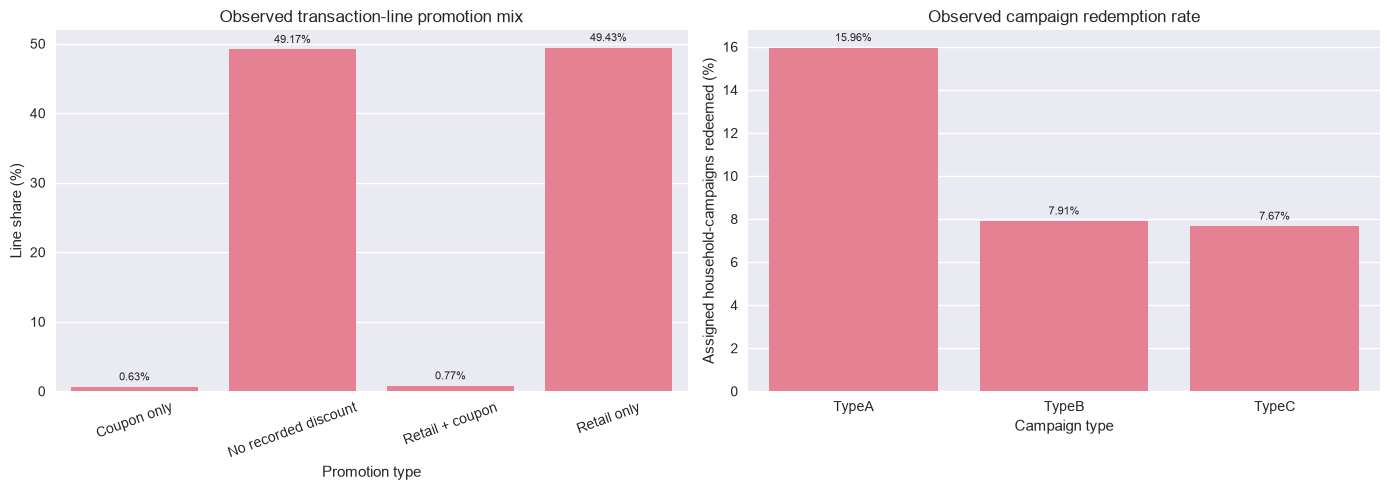

In [7]:
fig,axes=plt.subplots(1,2,figsize=(14,5))
sns.barplot(data=promotion_summary,x='promotion_type',y='line_share_pct',ax=axes[0]); axes[0].set(title='Observed transaction-line promotion mix',xlabel='Promotion type',ylabel='Line share (%)'); axes[0].tick_params(axis='x',rotation=20); add_bar_labels(axes[0],True)
sns.barplot(data=campaign_summary,x='DESCRIPTION',y='redemption_rate_pct',ax=axes[1]); axes[1].set(title='Observed campaign redemption rate',xlabel='Campaign type',ylabel='Assigned household-campaigns redeemed (%)'); add_bar_labels(axes[1],True)
plt.tight_layout(); plt.show()

## Problem Statement

Translate verified results into decisions while separating known facts, associations, and experimental needs. No new inferential question is introduced; duplicating H0/H1, power, and sample-size calculations would be statistically inappropriate. Upstream estimates and uncertainty are reproduced below.

## Question 1 — What findings are supported by executed analysis?

In [8]:
evidence=pd.DataFrame([
 {'finding':'Paired household basket association','effect':promotion_test.loc[0,'effect_value'],'ci_low':promotion_test.loc[0,'ci_low'],'ci_high':promotion_test.loc[0,'ci_high'],'p_value':promotion_test.loc[0,'p_value']},
 {'finding':'Household exposure vs quantity','effect':sensitivity_test.loc[0,'spearman_rho'],'ci_low':sensitivity_test.loc[0,'ci_low'],'ci_high':sensitivity_test.loc[0,'ci_high'],'p_value':sensitivity_test.loc[0,'p_value']},
 {'finding':'Exclusive Type A - Type B redemption','effect':coupon_test.loc[0,'rate_difference'],'ci_low':coupon_test.loc[0,'ci_low'],'ci_high':coupon_test.loc[0,'ci_high'],'p_value':coupon_test.loc[0,'p_value']}])
evidence['decision_at_0.05']=np.where(evidence.p_value<ALPHA,'Reject H0','Fail to reject H0'); display(evidence.round(4))

,finding,effect,ci_low,ci_high,p_value,decision_at_0.05
0,Paired household basket association,19.8959,19.3170,20.5759,0.0000,Reject H0
1,Household exposure vs quantity,0.1764,0.1090,0.2433,0.0000,Reject H0
2,Exclusive Type A - Type B redemption,0.0339,-0.0476,0.1153,0.4612,Fail to reject H0


## Question 2 — What actions are justified now?

In [9]:
repeat_rate=coupon_test.loc[0,'repeat_30d_rate']; top=promotion_summary.loc[promotion_summary.line_share_pct.idxmax()]
recommendations=pd.DataFrame([
 ['Measurement','Use household/store randomized holdouts before claiming lift.','Current comparisons are observational.'],
 ['Targeting','Use supported response scores only to prioritize tests.','Scores do not isolate price response.'],
 ['Coupons','Track delivery and maintain a non-redeemer holdout.',f'Observed 30-day eligible-product purchase rate is {100*repeat_rate:.2f}% without a counterfactual.'],
 ['Economics','Add unit cost, funding, and margin fields before optimizing depth.','No verified profit inputs exist.'],
 ['Data quality','Define quantity units by department and monitor extremes.','Quantity is highly skewed and may encode weighted items.']],columns=['area','recommended_action','evidence_or_guardrail'])
print(f"Largest observed line-share condition: {top.promotion_type} ({top.line_share_pct:.2f}%)."); display(recommendations)

Largest observed line-share condition: Retail only (49.43%).


,area,recommended_action,evidence_or_guardrail
0,Measurement,Use household/store randomized holdouts before...,Current comparisons are observational.
1,Targeting,Use supported response scores only to prioriti...,Scores do not isolate price response.
2,Coupons,Track delivery and maintain a non-redeemer hol...,Observed 30-day eligible-product purchase rate...
3,Economics,"Add unit cost, funding, and margin fields befo...",No verified profit inputs exist.
4,Data quality,Define quantity units by department and monito...,Quantity is highly skewed and may encode weigh...


## Question 3 — How should the next promotion experiment be designed?

In [10]:
display(pd.DataFrame({'design_element':['Unit','Assignment','Primary outcome','Guardrails','Duration','Analysis'],'recommendation':['Household or store chosen before exposure','Randomized eligible units plus untreated holdout','Pre-specified sales/quantity per assigned unit','Margin when available, stockouts, substitution, complaints','Complete seasonal cycles defined in advance','Effect, 95% CI, p-value, achieved sample, attrition']}))

,design_element,recommendation
0,Unit,Household or store chosen before exposure
1,Assignment,Randomized eligible units plus untreated holdout
2,Primary outcome,Pre-specified sales/quantity per assigned unit
3,Guardrails,"Margin when available, stockouts, substitution..."
4,Duration,Complete seasonal cycles defined in advance
5,Analysis,"Effect, 95% CI, p-value, achieved sample, attr..."


## Summary

- The evidence table carries effects, 95% intervals, p-values, and decisions from executed analyses.
- Actions are experiment and measurement priorities.
- No profit claim is made because costs and margins are absent.

## Insights

- Observational associations can rank hypotheses but not answer the counterfactual.
- The highest-value next step is a randomized, pre-powered holdout.
- Add margin and inventory data before economic optimization.